# 06 – Final Cost Comparison: lowest cost for the town
**Mock Data Science Challenge – Dataset A** (team notebook)

This notebook collects the results saved by the five model notebooks, compares them on **cost**, ranks them from lowest to highest cost, runs a
cost sensitivity analysis and writes the five ranked submission files.

**Before running:** put the files from each person's `results/` folder into a `results/` folder next to this notebook
(clone the team GitHub repo, or upload them when asked).

## 1. Setup
> 🔒 **Sections 1–4 are identical in every model notebook. Do not change them.** Using the same features, metric, split and folds is what makes the five models comparable in `06_Final_Cost_Comparison`.

In [1]:
# Core libraries
import os, json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# scikit-learn tools shared by all model notebooks
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, log_loss, confusion_matrix
from sklearn.inspection import permutation_importance

In [3]:
RANDOM_STATE = 42
TARGET = 'seasonal_vaccine'
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')

## 2. Load the data

In [4]:
TRAIN_PATH, TEST_PATH = 'dataset_A_training.csv', 'dataset_A_testing.csv'

# In Colab, upload the two CSV files if they are not already in the working folder
if not (os.path.exists(TRAIN_PATH) and os.path.exists(TEST_PATH)):
    from google.colab import files
    files.upload()

In [5]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print('Train:', train.shape, ' Test:', test.shape)

Train: (4756, 31)  Test: (4749, 30)


## 3. Features and evaluation metric (from notebook 00)

In [6]:
BINARY = ['behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
          'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home',
          'behavioral_touch_face', 'doctor_recc_seasonal', 'child_under_6_months',
          'health_worker', 'health_insurance']
ORDINAL_NUM = ['flu_concern', 'flu_knowledge', 'opinion_seas_vacc_effective',
               'opinion_seas_risk', 'opinion_seas_sick_from_vacc',
               'household_adults', 'household_children', 'number_chronic_med_conditions']

In [7]:
ORDERED_CAT = {
    'age_group': ['18 - 34 Years', '35 - 44 Years', '45 - 54 Years', '55 - 64 Years', '65+ Years'],
    'education': ['< 12 Years', '12 Years', 'Some College', 'College Graduate'],
    'income_poverty': ['Below Poverty', '<= $75,000, Above Poverty', '> $75,000'],
}
NOMINAL = ['race', 'sex', 'marital_status', 'rent_or_own', 'employment_status',
           'census_msa', 'employment_sector']
FEATURES = BINARY + ORDINAL_NUM + list(ORDERED_CAT) + NOMINAL

**Metric (derived in notebook 00).** Predicting 1 ("already vaccinated") for someone who is not means they are not offered a vaccine and risk
hospitalisation (FP = \$18,500). Predicting 0 for someone who is already vaccinated wastes a vaccine (FN = \$300).
We predict 1 only when $p > 18{,}500 / 18{,}800 \approx 0.984$.

In [8]:
COSTS = {'TP': 0, 'TN': 0, 'FP': 18_500, 'FN': 300}

def total_cost(y_true, y_pred, costs=COSTS):
    """Total $ cost of a set of 0/1 predictions."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tp * costs['TP'] + tn * costs['TN'] + fp * costs['FP'] + fn * costs['FN']

In [9]:
def cost_per_person(y_true, y_pred, costs=COSTS):
    """Average cost per respondent."""
    return total_cost(y_true, y_pred, costs) / len(y_true)

def bayes_threshold(costs=COSTS):
    """Probability above which predicting 1 is cheaper than predicting 0."""
    a, b = costs['FP'] - costs['TN'], costs['FN'] - costs['TP']
    return a / (a + b)

THRESHOLD = bayes_threshold()
print(f'Cost-optimal threshold: {THRESHOLD:.4f}')

Cost-optimal threshold: 0.9840


## 4. Recreate the same hold-out split (same seed as the model notebooks)

In [10]:
X, y = train[FEATURES], train[TARGET]
X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

## 5. Load the five models' results

In [11]:
MODEL_NAMES = ['LogReg', 'RandomForest', 'NeuralNet', 'ExtraTrees', 'SVM']
RESULTS_DIR = 'results'

# Colab: upload the result files if the folder is missing
if not os.path.isdir(RESULTS_DIR):
    from google.colab import files
    os.makedirs(RESULTS_DIR)
    for fname in files.upload():
        os.rename(fname, os.path.join(RESULTS_DIR, fname))

In [12]:
results = {}
for name in MODEL_NAMES:
    with open(f'{RESULTS_DIR}/{name}_results.json') as f:
        results[name] = json.load(f)
pd.DataFrame(results).T[['preprocessing', 'cv_log_loss', 'rcv_auc_mean', 'holdout_auc']]

,preprocessing,cv_log_loss,rcv_auc_mean,holdout_auc
LogReg,B_missing_aware,0.492929,0.846639,0.851578
RandomForest,B_missing_aware,0.485592,0.847267,0.8447
NeuralNet,B_missing_aware,0.489392,0.845964,0.8503
ExtraTrees,B_missing_aware,0.486972,0.847638,0.843537
SVM,B_missing_aware,0.487544,0.847535,0.849896


In [13]:
# Baseline "predict all 0" on exactly the same 15 CV folds and hold-out set
baseline_folds = [cost_per_person(y_dev.iloc[va], np.zeros(len(va))) for _, va in RCV.split(X_dev, y_dev)]
BASELINE_CV = np.mean(baseline_folds)
BASELINE_HOLD = cost_per_person(y_hold, np.zeros(len(y_hold)))
print(f'Baseline: CV ${BASELINE_CV:.2f} per person, hold-out ${BASELINE_HOLD:.2f} per person')

Baseline: CV $160.88 per person, hold-out $161.03 per person


## 6. Cost comparison for the town
The **town** is the population we make decisions for: the **4,749 residents in the test set**.

- **Cost per person** = mean over the 15 repeated-CV folds (the most reliable estimate).
- **Estimated town cost** = cost per person × 4,749.
- **Saving** = how much cheaper the model is than offering everyone a vaccine.
- The hold-out cost and the cost at the naive 0.5 threshold are included as checks.

In [14]:
TOWN_POPULATION = len(test)
rows = []
for name, r in results.items():
    rows.append({'model': name,
                 'cv_cost_per_person': r['rcv_cost_pp_mean'], 'cv_std': r['rcv_cost_pp_std'],
                 'holdout_cost_per_person': r['holdout_cost_pp'],
                 'est_town_cost': r['rcv_cost_pp_mean'] * TOWN_POPULATION,
                 'saving_vs_vaccinate_all': (BASELINE_CV - r['rcv_cost_pp_mean']) * TOWN_POPULATION,
                 'town_cost_at_t0.5': r['holdout_cost_pp_t05'] * TOWN_POPULATION,
                 'cv_log_loss': r['cv_log_loss']})
cost_table = pd.DataFrame(rows).set_index('model')

In [15]:
# Rank by estimated town cost (1 = lowest); ties broken by CV log loss
cost_table = cost_table.sort_values(['est_town_cost', 'cv_log_loss'])
cost_table.insert(0, 'rank', range(1, len(cost_table) + 1))
baseline_row = pd.DataFrame({'rank': ['baseline'], 'cv_cost_per_person': [BASELINE_CV], 'cv_std': [np.std(baseline_folds, ddof=1)],
                             'holdout_cost_per_person': [BASELINE_HOLD], 'est_town_cost': [BASELINE_CV * TOWN_POPULATION],
                             'saving_vs_vaccinate_all': [0.0]}, index=['Predict_all_0 (vaccinate everyone)'])
pd.concat([cost_table, baseline_row]).drop(columns='cv_log_loss').round(2)

,rank,cv_cost_per_person,cv_std,holdout_cost_per_person,est_town_cost,saving_vs_vaccinate_all,town_cost_at_t0.5
ExtraTrees,1,159.67,0.68,160.71,758292.53,5742.38,9671597.90
LogReg,2,160.25,0.46,160.71,761038.83,2996.08,10485712.18
SVM,3,160.25,0.52,160.40,761038.99,2995.92,10575005.36
NeuralNet,4,160.59,0.36,160.71,762661.68,1373.23,10948639.92
RandomForest,5,160.67,0.32,161.03,763036.27,998.64,10582488.03
Predict_all_0 (vaccinate everyone),baseline,160.88,0.09,161.03,764034.91,0.00,NaN


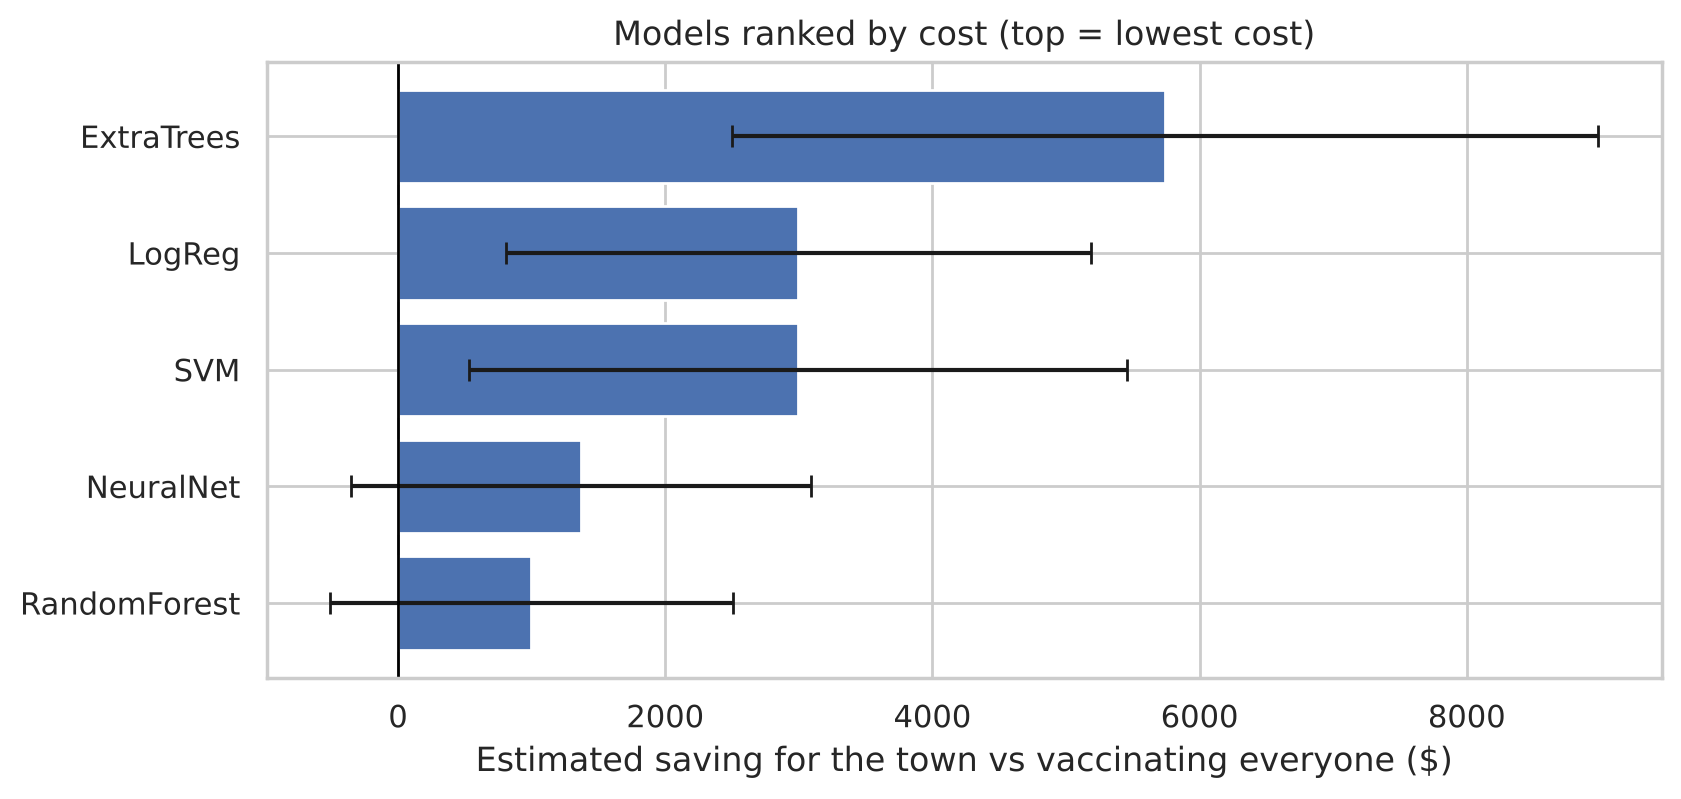

In [16]:
# Saving for the town vs vaccinating everyone (error bars = 1 std across the 15 CV folds)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(cost_table.index[::-1], cost_table.saving_vs_vaccinate_all[::-1],
        xerr=(cost_table.cv_std * TOWN_POPULATION)[::-1], capsize=4,
        color=['#4c72b0' if v >= 0 else '#c44e52' for v in cost_table.saving_vs_vaccinate_all[::-1]])
ax.axvline(0, c='black', lw=1)
ax.set_xlabel('Estimated saving for the town vs vaccinating everyone ($)')
ax.set_title('Models ranked by cost (top = lowest cost)'); plt.show()

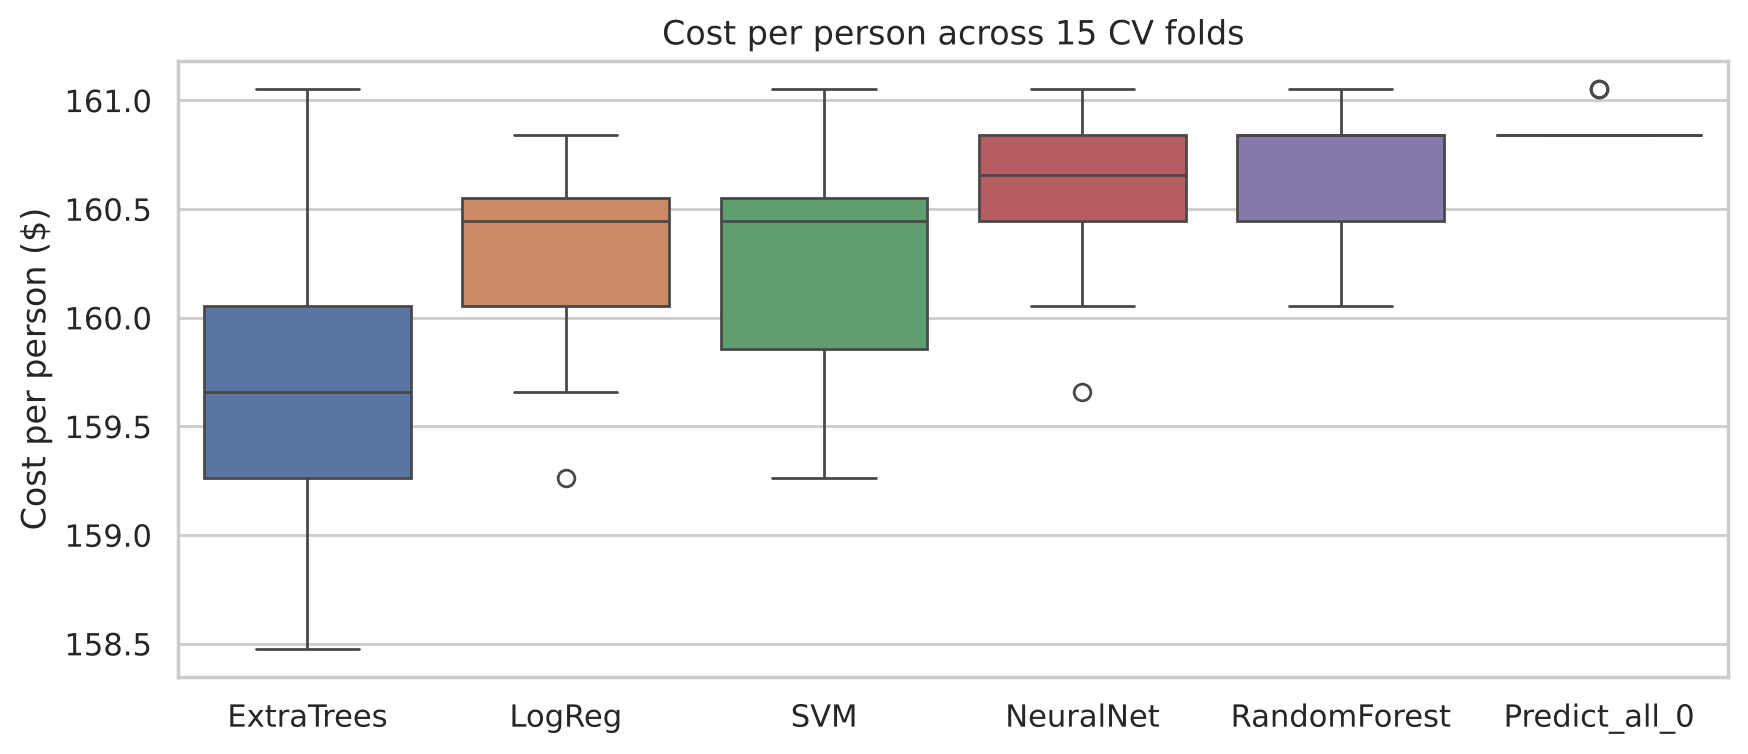

In [17]:
# Fold-by-fold cost for every model
folds = pd.DataFrame({name: r['rcv_cost_pp_folds'] for name, r in results.items()})
folds['Predict_all_0'] = baseline_folds
plt.figure(figsize=(10, 4))
sns.boxplot(data=folds[list(cost_table.index) + ['Predict_all_0']])
plt.ylabel('Cost per person ($)'); plt.title('Cost per person across 15 CV folds'); plt.show()

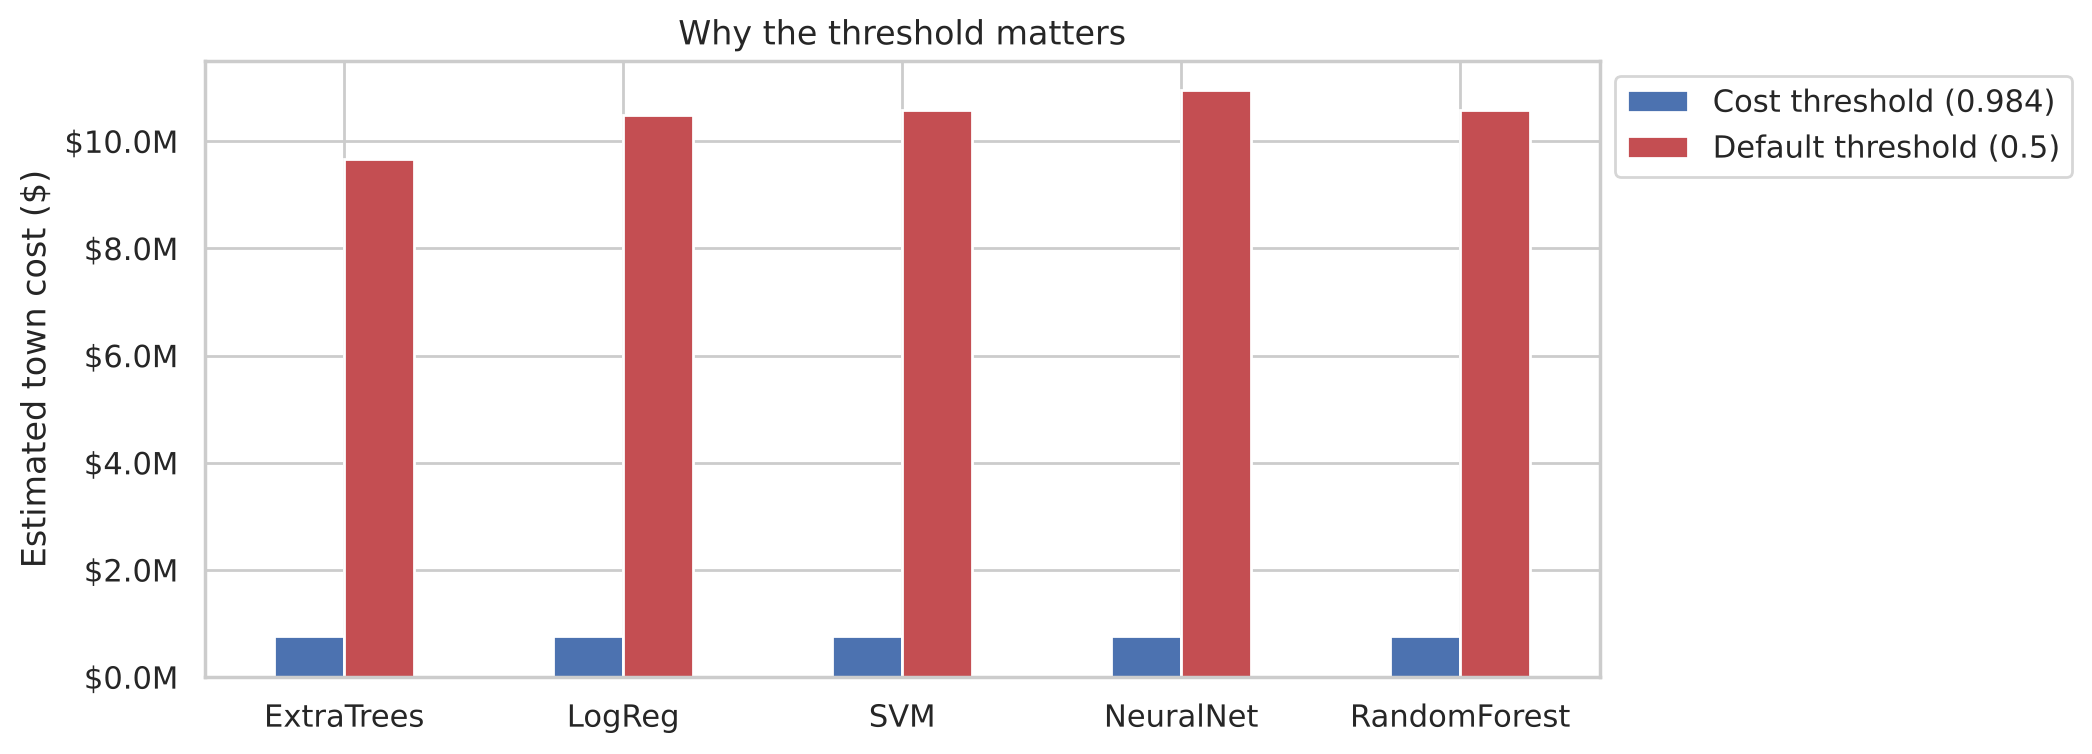

In [18]:
# Cost-optimal threshold vs default 0.5 threshold
comp = cost_table[['est_town_cost', 'town_cost_at_t0.5']].rename(
    columns={'est_town_cost': f'Cost threshold ({THRESHOLD:.3f})', 'town_cost_at_t0.5': 'Default threshold (0.5)'})
ax = comp.plot.bar(figsize=(9, 4), color=['#4c72b0', '#c44e52'])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v / 1e6:.1f}M'))
ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); ax.set_xlabel('')
ax.set_ylabel('Estimated town cost ($)'); ax.set_title('Why the threshold matters')
plt.xticks(rotation=0); plt.show()

In [19]:
best = cost_table.index[0]
print(f'Lowest-cost model for the town: {best}')
print(f'Estimated town cost: ${cost_table.loc[best, "est_town_cost"]:,.0f}')
print(f'Saving vs vaccinating everyone: ${cost_table.loc[best, "saving_vs_vaccinate_all"]:,.0f}')

Lowest-cost model for the town: ExtraTrees
Estimated town cost: $758,293
Saving vs vaccinating everyone: $5,742


**Final ranking (lowest cost for the town first)**

| Rank | Model | Est. town cost | Saving vs vaccinating everyone |
|---|---|---|---|
| 1 | Extra Trees | ≈ \$758,300 | ≈ \$5,700 |
| 2 | Logistic regression | ≈ \$761,000 | ≈ \$3,000 |
| 3 | SVM | ≈ \$761,000 | ≈ \$3,000 |
| 4 | Neural network | ≈ \$762,700 | ≈ \$1,400 |
| 5 | Random forest | ≈ \$763,000 | ≈ \$1,000 |

- **Extra Trees gives the lowest cost for the town**, saving almost twice as much as the next model.
- **All five models save money** against vaccinating everyone, and each one beats or matches that baseline on every one of the 15 CV folds.
- Logistic regression and SVM are essentially tied. SVM was slightly better on the hold-out set, but we rank by the 15-fold CV estimate, which is more reliable.
- With the default 0.5 threshold, every model would cost the town about **\$10 million**, roughly 13–14× more. The cost-based threshold matters far more than the choice of model.

## 7. Cost sensitivity analysis
The brief does not give the cost formula, so we check whether the ranking holds under other reasonable interpretations, using each model's hold-out probabilities.
If hospitalisation is not certain (probability $h$), the cost of a false positive becomes $h \times$ \$18,500.

In [20]:
SCENARIOS = {
    'Main: FP=18500, FN=300': {'TP': 0, 'TN': 0, 'FP': 18_500, 'FN': 300},
    'h=10%: FP=1850': {'TP': 0, 'TN': 0, 'FP': 1_850, 'FN': 300},
    'h=5%: FP=925': {'TP': 0, 'TN': 0, 'FP': 925, 'FN': 300},
}
hold_proba = {name: pd.read_csv(f'{RESULTS_DIR}/{name}_holdout_proba.csv', index_col=0)['p']
              .reindex(X_hold.index).values for name in MODEL_NAMES}

In [21]:
sens = {}
for scen, c in SCENARIOS.items():
    t = bayes_threshold(c)
    sens[f'{scen} (t={t:.3f})'] = {name: cost_per_person(y_hold, (p >= t).astype(int), c)
                                    for name, p in hold_proba.items()}
    sens[f'{scen} (t={t:.3f})']['Predict_all_0'] = cost_per_person(y_hold, np.zeros(len(y_hold)), c)
pd.DataFrame(sens).round(2)

,"Main: FP=18500, FN=300 (t=0.984)",h=10%: FP=1850 (t=0.860),h=5%: FP=925 (t=0.755)
LogReg,160.71,130.41,102.49
RandomForest,161.03,135.40,115.34
NeuralNet,160.71,125.37,108.93
ExtraTrees,160.71,137.66,121.98
SVM,160.40,127.99,109.30
Predict_all_0,161.03,161.03,161.03


## 8. Submission – five models ranked by cost
Each model's test predictions are copied into `submissions/`, numbered by the cost ranking (rank 1 = lowest expected cost for the town).

> ⚠️ Check the column names and format against the official submission instructions.

In [22]:
TEAM_NAME = 'TeamXX'   # <-- change to our team name
os.makedirs('submissions', exist_ok=True)
for rank, name in enumerate(cost_table.index, start=1):
    sub = pd.read_csv(f'{RESULTS_DIR}/{name}_test_predictions.csv')
    assert len(sub) == len(test) and set(sub.columns) == {'respondent_id', TARGET}
    path = f'submissions/{TEAM_NAME}_rank{rank}_{name}.csv'
    sub.to_csv(path, index=False)
    print(f'{path}: {sub[TARGET].sum()} respondents predicted as vaccinated')

submissions/TeamXX_rank1_ExtraTrees.csv: 10 respondents predicted as vaccinated
submissions/TeamXX_rank2_LogReg.csv: 12 respondents predicted as vaccinated
submissions/TeamXX_rank3_SVM.csv: 14 respondents predicted as vaccinated
submissions/TeamXX_rank4_NeuralNet.csv: 5 respondents predicted as vaccinated
submissions/TeamXX_rank5_RandomForest.csv: 0 respondents predicted as vaccinated


In [23]:
try:
    from google.colab import files
    import shutil
    shutil.make_archive('submissions', 'zip', 'submissions')
    files.download('submissions.zip')
except ImportError:
    pass

## Conclusions
- **Metric:** total misclassification cost. Wrongly assuming someone is vaccinated costs \$18,500, and an unnecessary vaccine costs \$300. This gives a decision threshold of **0.984**.
- **Ranking by cost for the town:** 1 Extra Trees, 2 Logistic regression, 3 SVM, 4 Neural network, 5 Random forest. All five beat the "vaccinate everyone" baseline.
- **Why savings are small:** one wrong "vaccinated" call costs as much as about 60 unnecessary vaccines, so a model can only act on the few people it is almost certain about.
  Well-regularised models that average many opinions (Extra Trees) or shrink coefficients (logistic regression) do this best.
- **Sensitivity:** if hospitalisation is less certain, every model saves far more (e.g. about \$40–60 per person at $h$ = 5%). The neural network (at $h$ = 10%) and logistic regression (at $h$ = 5%) then come out best, and Extra Trees comes last, so the ranking depends on the cost interpretation.
- **Drivers of vaccination**, consistent across all five models: perceived risk of flu, doctor recommendation, age and belief in vaccine effectiveness.